# VGG-16: ajuste, ejecución definitiva y evaluación

Este notebook entrena y evalúa VGG-16 con las funciones de `src/` (`train.py`, `tune.py`,
`final.py`, `results.py`, `evaluation.py`, `gradcam.py`). El modelo se elige con la variable
`MODELO` de la sección 1; el resto del notebook es igual para los tres modelos base. Todos los
parámetros se leen de `configs/base.yaml` y `configs/<modelo>.yaml`. El ajuste usa
solo los pliegues de entrenamiento; test se evalúa únicamente en la ejecución definitiva. Si
faltan resultados, cada sección muestra un aviso y el notebook continúa.

## 1. Configuración

Modelo y flags de reejecución. Con un flag en `False`, la sección correspondiente carga los
resultados guardados y, si no existen, muestra un aviso sin ejecutar nada. Con `True`, llama a
`src.tune` o `src.final`, que reutilizan las corridas terminadas y ejecutan las pendientes.

In [1]:
MODELO = "vgg16"
RERUN_AJUSTE = False
RERUN_FINAL = False

In [2]:
import pandas as pd

from src import data, evaluation, final, gradcam, results
from src.report import show
from src.train import build_model, configure_runtime, load_model_config
from src.tune import run_tuning
from src.utils import environment_info, set_seed

Carga de las configuraciones, memory growth en la GPU, política de precisión
(`train.mixed_precision`) y semilla (`seed` de `base.yaml`).

In [3]:
cfg = data.load_config()
cfg_modelo = load_model_config(MODELO)
configure_runtime(cfg)
set_seed(cfg["seed"], deterministic=cfg["train"]["deterministic"])
rutas = cfg["paths"]
cfg_train = cfg["train"]
cfg_eval = cfg["evaluation"]
ALPHA = cfg["benchmark"]["alpha"]

pd.Series({
    "modelo": cfg_modelo["name"],
    "aplicación de Keras": cfg_modelo["keras_application"],
    "pesos": cfg_modelo["weights"],
    "entrada": f"{cfg_modelo['input_size']} x {cfg_modelo['input_size']}",
    "capa de Grad-CAM": cfg_modelo.get("gradcam_layer"),
    "clases": ", ".join(data.class_names(cfg)),
    "batch_size": cfg_train["batch_size"],
    "mixed_precision": cfg_train["mixed_precision"],
    "deterministic": cfg_train["deterministic"],
    "épocas fase A": cfg_train["warmup"]["epochs"],
    "épocas máximas fase B": cfg_train["finetune"]["max_epochs"],
    "semilla del notebook": cfg["seed"],
}, name="valor").to_frame()

2026-11-28 05:32:55.606465: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


,valor
modelo,vgg16
aplicación de Keras,VGG16
pesos,imagenet
entrada,224 x 224
capa de Grad-CAM,block5_conv3
clases,"akiec, bcc, bkl, df, mel, nv, vasc"
batch_size,32
mixed_precision,True
deterministic,False
épocas fase A,5


GPU detectada y versiones de Python, TensorFlow, Keras, CUDA y cuDNN (estas dos, las de
compilación de TensorFlow).

In [4]:
results.environment_table(environment_info())

,valor
python,3.11.18
tensorflow,2.20.0
keras,3.15.1
cuda,12.5.1
cudnn,9
platform,Linux-7.2.11-300.fc45.x86_64-x86_64-with-glibc...
gpu,ninguna


## 2. Modelo

Arquitectura: entrada en [0, 255], `preprocess_input` de la aplicación dentro del modelo, backbone
anidado con `training=False` y cabeza: `Flatten`, `fc1` (4096) con sus pesos de ImageNet, `Dropout`, `fc2` (4096) con sus pesos de ImageNet, `Dropout` y `Dense` softmax en float32, en lugar de la capa `predictions` de 1000 clases. El backbone son los cinco bloques convolucionales; en la fase A se entrenan fc1, fc2 y la salida. El dropout es el del YAML, o 0.0 si aún es null
(no cambia el número de parámetros).

In [5]:
modelo = build_model(cfg, MODELO)
modelo.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone (Functional)           │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │        28,679 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,289,223 (512.27 MB)

 Trainable params: 119,574,535 (456.14 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Parámetros entrenables y no entrenables con el backbone congelado (fase A) y descongelado (fase B).
VGG-16 no tiene BatchNormalization, así que en la fase B no quedan parámetros no entrenables.

In [6]:
results.model_parameter_table(modelo)

,trainable,non_trainable,total
backbone congelado,119574535,14714688,134289223
backbone descongelado,134289223,0,134289223


## 3. Ajuste de hiperparámetros

Búsqueda aleatoria de `train.tuning`: `n_trials` configuraciones muestreadas con `sampler_seed`
(las mismas para los tres modelos), una corrida por configuración con `seed` y `val_fold` fijos y la
fase B limitada a `tuning.max_epochs`.

In [7]:
pd.DataFrame(cfg_train["tuning"]["space"]).T

,type,low,high,values
learning_rate,loguniform,0.00001,0.001,NaN
weight_decay,loguniform,0.000001,0.001,NaN
dropout,choice,NaN,NaN,"[0.0, 0.2, 0.4]"


### 3.1 Ejecución

Carga `outputs/tuning/<modelo>/trials.csv` si existe; con `RERUN_AJUSTE = True`, llama a
`run_tuning`. Si el ajuste se interrumpió, el archivo contiene solo los ensayos terminados.

In [8]:
dir_ajuste = rutas["tuning_dir"] / MODELO
ensayos, origen = results.load_or_run(
    dir_ajuste / "trials.csv", lambda: run_tuning(cfg, MODELO), RERUN_AJUSTE,
    missing_message=f"no hay ensayos de ajuste de {MODELO}; ejecuta `python -m src.tune --model {MODELO}` "
                    "o pon RERUN_AJUSTE = True.")
results.load_status(dir_ajuste / "trials.csv", ensayos, origen, "ensayos")

,valor
archivo,outputs/tuning/vgg16/trials.csv
estado,cargado
ensayos,6


### 3.2 Resultados

Configuraciones ordenadas por exactitud balanceada de validación (`best_epoch` es la época de la
fase B cuyos pesos se restauraron).

In [9]:
results.tuning_table(ensayos)

,trial,learning_rate,weight_decay,dropout,val_balanced_accuracy,best_epoch,epochs_warmup,epochs_finetune,train_time_s,run_dir,excluded,excluded_reason
0,1,0.000055,0.000012,0.2,0.672592,15,5,15,534.459607,outputs/runs/vgg16/tuning_t01/s0_f0,False,NaN
1,0,0.000023,0.000083,0.2,0.658811,9,5,14,670.546001,outputs/runs/vgg16/tuning_t00/s0_f0,False,NaN
2,3,0.000202,0.000008,0.0,0.568219,15,5,15,528.500607,outputs/runs/vgg16/tuning_t03/s0_f0,False,NaN
3,2,0.000381,0.000519,0.4,0.412393,12,5,15,529.612999,outputs/runs/vgg16/tuning_t02/s0_f0,False,NaN
4,5,0.000320,0.000035,0.2,0.230211,4,5,9,361.471961,outputs/runs/vgg16/tuning_t05/s0_f0,False,NaN
5,4,0.000859,0.000575,0.0,0.198076,10,5,15,518.925979,outputs/runs/vgg16/tuning_t04/s0_f0,False,NaN


Mejor configuración según `best.json` (se escribe al terminar todos los ensayos).

In [10]:
mejor = results.load_json_or_missing(
    dir_ajuste / "best.json",
    f"no existe outputs/tuning/{MODELO}/best.json; se escribe al terminar `python -m src.tune --model {MODELO}`.")
results.best_table(mejor)

,valor
ensayo,1.000000
learning_rate,0.000055
weight_decay,0.000012
dropout,0.200000
val_balanced_accuracy,0.672592
best_epoch,15.000000


Exactitud balanceada de validación frente a cada hiperparámetro (eje logarítmico para los de
distribución loguniforme). El número junto a cada punto es el índice del ensayo; el círculo rojo
marca el mejor.

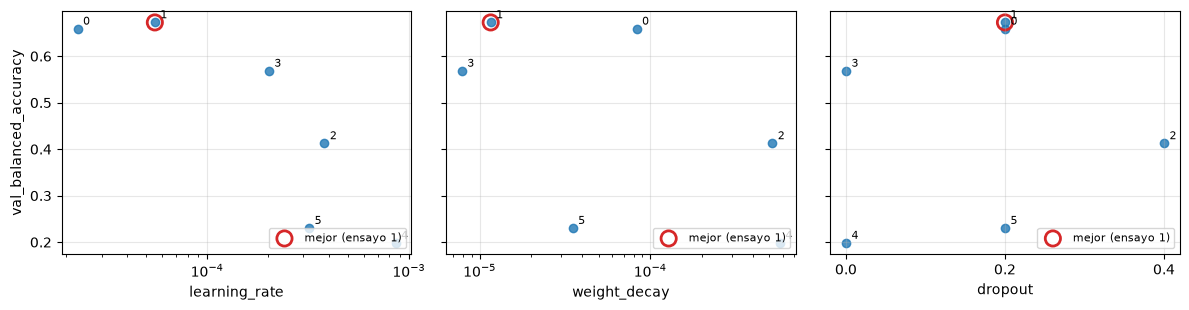

In [11]:
show(results.plot_metric_vs_hparams(ensayos, cfg_train["tuning"]["space"], best_trial=results.best_trial(mejor)))

### 3.3 Hiperparámetros seleccionados

Valores de la sección `hyperparameters` de `configs/<modelo>.yaml` frente a `best.json`. Se emite
un aviso si alguno es null o difiere.

In [12]:
results.compare_hparams(cfg_modelo, mejor)

/tmp/ipykernel_227164/1570348254.py:1: UserWarning: configs/vgg16.yaml: learning_rate (null en el YAML), weight_decay (null en el YAML), dropout (null en el YAML)
  results.compare_hparams(cfg_modelo, mejor)


,yaml,best.json,estado
learning_rate,None,0.000055,null en el YAML
weight_decay,None,0.000012,null en el YAML
dropout,None,0.2,null en el YAML


## 4. Estudio piloto

Estudio piloto omitido (desviación D2, capítulo 7).

## 5. Ejecución definitiva

Validación cruzada repetida: producto `final.seeds` x `final.folds` de `base.yaml`, con los
hiperparámetros del YAML del modelo. Cada corrida evalúa validación y test, calcula las métricas de
su train sin aumento ni dropout y guarda sus pesos. El número de semillas se fijó por cómputo en `preregistro.md`
(desviación D3, capítulo 7).

In [13]:
final.config_table(cfg)

,valor
etiqueta,final
semillas,[0]
pliegues,"[0, 1, 2, 3, 4]"
corridas,5
evaluación de test,True
métricas de train sin aumento,True
pesos guardados,True


### 5.1 Ejecución

Con `RERUN_FINAL = False`, carga las corridas definitivas terminadas sin ejecutar nada; con `True`,
llama a `run_final`, que reutiliza las terminadas y ejecuta las pendientes (equivale a
`python -m src.final --model <modelo>`). Resumen y estado de cada corrida prevista.

In [14]:
corridas, estado = final.load_or_run_final(cfg, MODELO, rerun=RERUN_FINAL)
show(results.runs_summary(corridas))
final.status_summary(estado)

,valor
corridas terminadas,5
corridas,"s0_f0, s0_f1, s0_f2, s0_f3, s0_f4"


,corridas
previstas,5
terminadas,5
pendientes,0


In [15]:
estado

,seed,val_fold,estado,run_dir
0,0,0,terminada,outputs/runs/vgg16/final/s0_f0
1,0,1,terminada,outputs/runs/vgg16/final/s0_f1
2,0,2,terminada,outputs/runs/vgg16/final/s0_f2
3,0,3,terminada,outputs/runs/vgg16/final/s0_f3
4,0,4,terminada,outputs/runs/vgg16/final/s0_f4


### 5.2 Resultados por corrida

Métricas globales de validación por corrida con los pesos restaurados. Al final, media, desviación
estándar (ddof = 1) e intervalo de confianza al 95 % de la media por t de Student
(`ci95_low`, `ci95_high`).

In [16]:
results.add_summary_rows(results.run_metrics_table(corridas, split="val"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.671594,0.701805,0.546285,0.725204,0.922243,0.582693,0.499377,0.047522
s0_f1,0.688222,0.718695,0.600380,0.737807,0.931464,0.683692,0.540780,0.054014
s0_f2,0.772951,0.756552,0.681621,0.773244,0.953009,0.779157,0.602981,0.054655
s0_f3,0.647366,0.619685,0.507660,0.661355,0.902482,0.605949,0.432745,0.046030
s0_f4,0.684994,0.722028,0.598294,0.747598,0.939939,0.667763,0.546741,0.049850
mean,0.693025,0.703753,0.586848,0.729042,0.929828,0.663851,0.524525,0.050414
std,0.047486,0.051030,0.065598,0.041747,0.019024,0.076882,0.063185,0.003836
ci95_low,0.634064,0.640392,0.505397,0.677206,0.906207,0.568388,0.446070,0.045652
ci95_high,0.751987,0.767115,0.668298,0.780877,0.953449,0.759313,0.602979,0.055177


Las mismas métricas sobre test.

In [17]:
results.add_summary_rows(results.run_metrics_table(corridas, split="test"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.593046,0.696716,0.524996,0.719082,0.902943,0.572568,0.476606,0.047058
s0_f1,0.682253,0.737247,0.626558,0.755785,0.915467,0.662289,0.567856,0.038242
s0_f2,0.653716,0.752621,0.623777,0.769121,0.925443,0.657907,0.584315,0.052095
s0_f3,0.613654,0.638015,0.507653,0.677726,0.896571,0.559907,0.457085,0.041317
s0_f4,0.668719,0.724668,0.606944,0.746951,0.922313,0.631767,0.550271,0.042844
mean,0.642278,0.709853,0.577986,0.733733,0.912547,0.616887,0.527227,0.044311
std,0.037653,0.045089,0.057117,0.036279,0.012427,0.047896,0.056840,0.005387
ci95_low,0.595525,0.653867,0.507066,0.688686,0.897118,0.557416,0.456651,0.037622
ci95_high,0.689030,0.765839,0.648905,0.778779,0.927977,0.676359,0.597803,0.051001


Precisión, sensibilidad y F1 por clase en test: media y desviación estándar entre corridas.

In [18]:
por_clase_test = results.per_class_table(corridas, split="test")
results.per_class_summary(por_clase_test)

precision              recall                  f1          
           mean       std      mean       std      mean       std
class                                                            
akiec  0.390731  0.086809  0.513043  0.045079  0.440054  0.066869
bcc    0.620648  0.060979  0.748649  0.107090  0.672436  0.044072
bkl    0.458205  0.080100  0.591083  0.145831  0.515456  0.106322
df     0.288186  0.140894  0.564706  0.089210  0.358554  0.119417
mel    0.365064  0.056402  0.532075  0.080861  0.430029  0.057244
nv     0.942705  0.016524  0.766388  0.050491  0.844334  0.027023
vasc   0.792756  0.073120  0.780000  0.027386  0.785038  0.041471

Matriz de confusión de test acumulada sobre las corridas y normalizada por fila.

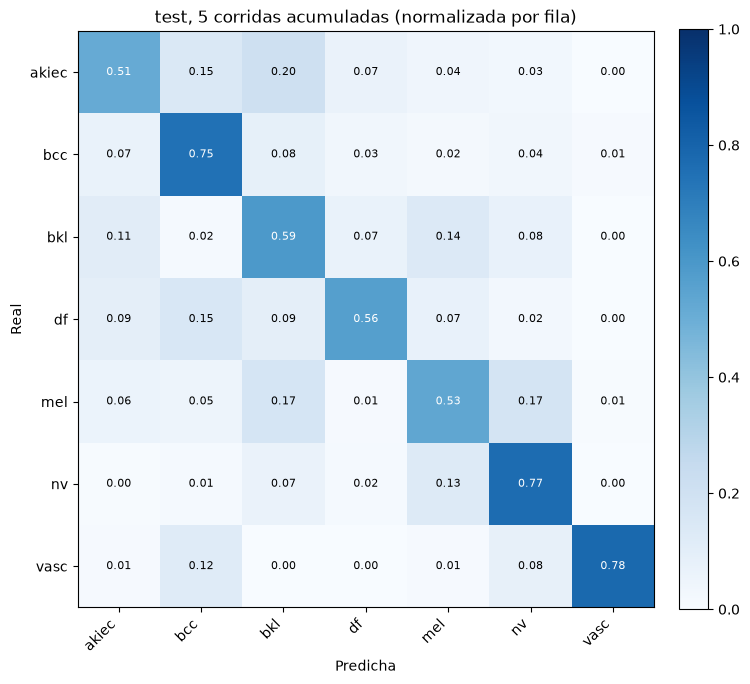

In [19]:
show(results.plot_pooled_confusion(corridas, split="test"))

Costo computacional por corrida (con la inferencia por imagen en validación, test y train) y épocas
de la fase B ejecutadas y restauradas.

In [20]:
results.add_mean_std(results.cost_table(corridas))

,warmup_s,finetune_s,total_s,epochs_warmup,epochs_finetune,finetune_s_per_epoch,inference_ms_per_image_val,inference_ms_per_image_test,inference_ms_per_image_train,trainable_params_finetune,non_trainable_params_finetune,gpu
s0_f0,77.070703,514.595665,591.666369,5.0,17.000000,30.270333,0.788696,5.863589,1.172552,134289223.0,0.0,NVIDIA L4
s0_f1,77.218842,828.018232,905.237074,5.0,28.000000,29.572080,0.778282,1.775201,0.983445,134289223.0,0.0,NVIDIA L4
s0_f2,75.607171,884.084652,959.691823,5.0,30.000000,29.469488,0.783654,1.774431,0.992612,134289223.0,0.0,NVIDIA L4
s0_f3,76.022758,602.719147,678.741905,5.0,20.000000,30.135957,0.791951,1.860457,1.006864,134289223.0,0.0,NVIDIA L4
s0_f4,85.455434,932.246091,1017.701525,5.0,30.000000,31.074870,0.798548,1.897929,0.788838,134289223.0,0.0,NVIDIA L4
mean,78.274982,752.332758,830.607739,5.0,25.000000,30.104546,0.788226,2.634321,0.988862,134289223.0,0.0,NaN
std,4.071681,183.274942,185.332494,0.0,6.082763,0.643587,0.007753,1.806019,0.136124,0.0,0.0,NaN


In [21]:
results.restored_epochs_table(corridas)

,finetune_run,finetune_best
s0_f0,17.000000,12.00000
s0_f1,28.000000,23.00000
s0_f2,30.000000,28.00000
s0_f3,20.000000,15.00000
s0_f4,30.000000,27.00000
mean,25.000000,21.00000
std,6.082763,7.17635


### 5.3 Curvas de entrenamiento

Curvas de todas las corridas definitivas superpuestas: una línea fina por corrida y la media por
época global en negro (con las corridas que llegan a esa época). La línea discontinua marca el paso
de la fase A a la B.

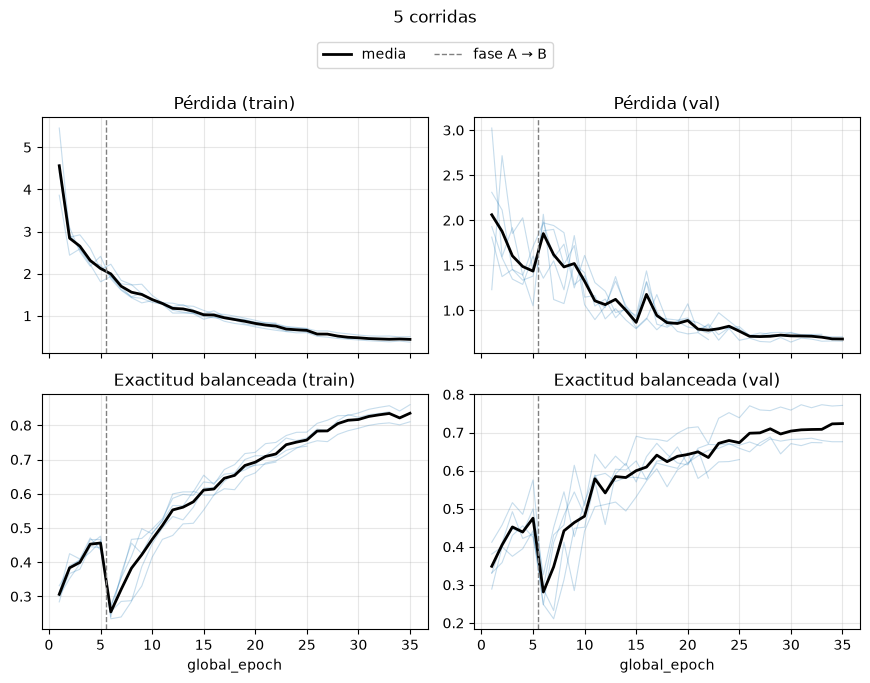

In [22]:
show(results.plot_training_curves_overlay(results.load_histories(corridas)))

## 6. Evaluación

Análisis de las predicciones guardadas de las corridas definitivas sobre `evaluation.split` (test),
con los parámetros de la sección `evaluation` de `base.yaml`. Carga de las probabilidades de todas
las corridas y de los metadatos.

In [23]:
pred_test = evaluation.load_predictions(corridas, cfg_eval["split"])
metadatos = evaluation.load_metadata_or_missing(cfg)
evaluation.predictions_summary(pred_test)

,valor
corridas,5
imagenes,1431
predicciones,7155


### 6.1 Robustez por subgrupos

Exactitud balanceada, exactitud y F1 macro de test por fuente (`dataset`), método diagnóstico
(`dx_type`) y localización: media y desviación estándar entre corridas e imágenes por corrida. F1
macro se promedia sobre las clases presentes en cada subgrupo. `pocas_imagenes` marca los subgrupos
con menos de `subgroup_min_n` imágenes.

In [24]:
subgrupos = evaluation.subgroup_report(pred_test, metadatos, cfg_eval["subgroups"],
                                       cfg_eval["subgroup_metrics"], cfg_eval["subgroup_min_n"])
show(subgrupos)

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:6

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

**dataset**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dataset,,,,,,,,,
vidir_molemax,567.0,5,0.690890,0.098749,0.940388,0.012558,0.596285,0.113519,False
vidir_modern,455.0,5,0.536221,0.056462,0.568352,0.072504,0.501121,0.052615,False
rosendahl,330.0,5,0.517629,0.042094,0.529091,0.067610,0.491780,0.063527,False
vienna_dias,79.0,5,0.688571,0.139912,0.625316,0.141693,0.616837,0.166281,False


**dx_type**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dx_type,,,,,,,,,
histo,776.0,5,0.564454,0.045820,0.542526,0.063876,0.518738,0.062045,False
follow_up,530.0,5,0.964528,0.008268,0.964528,0.008268,0.981929,0.004287,False
consensus,118.0,5,0.747753,0.068232,0.652542,0.109352,0.732229,0.111583,False
confocal,7.0,5,0.942857,0.127775,0.942857,0.127775,0.966667,0.074536,True


**localization**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
localization,,,,,,,,,
back,323.0,5,0.677560,0.045838,0.641486,0.064956,0.572569,0.054983,False
lower extremity,310.0,5,0.636634,0.036445,0.776129,0.039151,0.589712,0.059007,False
trunk,197.0,5,0.628651,0.178907,0.832487,0.044687,0.602648,0.150758,False
upper extremity,156.0,5,0.637963,0.042097,0.662821,0.052977,0.553155,0.072027,False
abdomen,147.0,5,0.652677,0.096069,0.795918,0.046138,0.563187,0.073594,False
face,84.0,5,0.573810,0.048513,0.630952,0.081180,0.581138,0.055137,False
foot,59.0,5,0.542618,0.180812,0.718644,0.025705,0.512333,0.069454,False
chest,52.0,5,0.644762,0.142977,0.546154,0.079987,0.565831,0.114151,False
unknown,34.0,5,0.640625,0.252671,0.588235,0.110049,0.609727,0.196018,False


Exactitud balanceada por subgrupo con la desviación estándar entre corridas como barra de error;
en gris, los subgrupos con pocas imágenes.

**dataset**

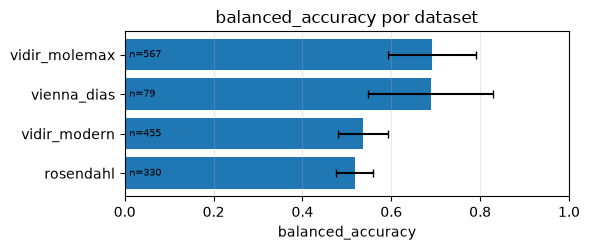

**dx_type**

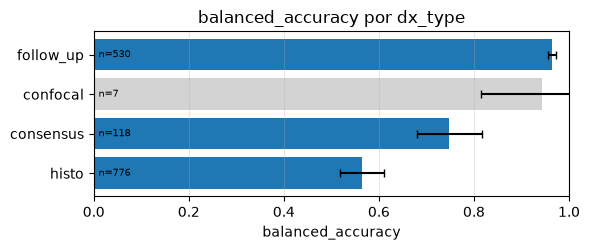

**localization**

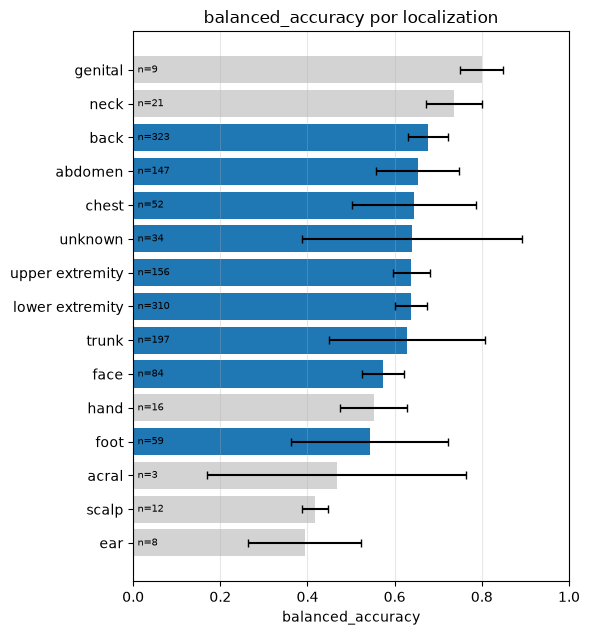

In [25]:
show(evaluation.plot_subgroup_report(subgrupos, "balanced_accuracy"))

### 6.2 Diagnóstico de sobreajuste

Métricas en el train de cada corrida (sin aumento de datos y sin dropout), en validación y en test,
y las brechas train - val y val - test: media y desviación estándar entre corridas.

In [26]:
sobreajuste = evaluation.overfitting_table(corridas, cfg_eval["overfitting_metrics"])
evaluation.overfitting_summary(sobreajuste, cfg_eval["overfitting_metrics"])

,train_mean,train_std,val_mean,val_std,test_mean,test_std,gap_train_val_mean,gap_train_val_std,gap_val_test_mean,gap_val_test_std
balanced_accuracy,0.799098,0.070426,0.693025,0.047486,0.642278,0.037653,0.106073,0.047774,0.050748,0.047294
accuracy,0.743126,0.061355,0.703753,0.051030,0.709853,0.045089,0.039373,0.021045,-0.006100,0.011645
f1_macro,0.677255,0.100217,0.586848,0.065598,0.577986,0.057117,0.090407,0.044579,0.008862,0.032275
cross_entropy,0.650941,0.165047,0.766888,0.095161,0.774748,0.083433,-0.115948,0.083942,-0.007860,0.026975


Exactitud balanceada en train, validación y test por corrida y su media.

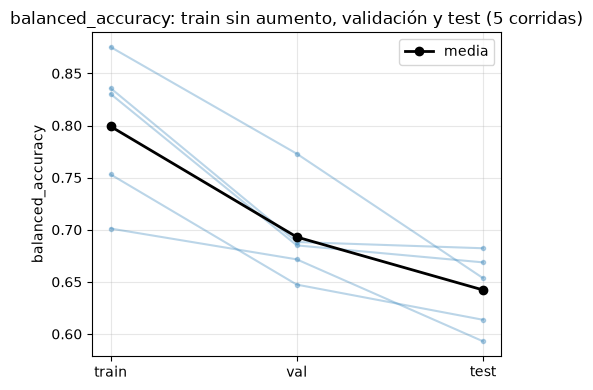

In [27]:
show(evaluation.plot_overfitting(sobreajuste, "balanced_accuracy"))

Valores por corrida.

In [28]:
sobreajuste

,balanced_accuracy_train,balanced_accuracy_val,balanced_accuracy_test,balanced_accuracy_gap_train_val,balanced_accuracy_gap_val_test,accuracy_train,accuracy_val,accuracy_test,accuracy_gap_train_val,accuracy_gap_val_test,f1_macro_train,f1_macro_val,f1_macro_test,f1_macro_gap_train_val,f1_macro_gap_val_test,cross_entropy_train,cross_entropy_val,cross_entropy_test,cross_entropy_gap_train_val,cross_entropy_gap_val_test
s0_f0,0.701131,0.671594,0.593046,0.029537,0.078547,0.706568,0.701805,0.696716,0.004762,0.005090,0.570604,0.546285,0.524996,0.024319,0.021288,0.777184,0.784179,0.801538,-0.006994,-0.017359
s0_f1,0.835793,0.688222,0.682253,0.147571,0.005969,0.774574,0.718695,0.737247,0.055879,-0.018551,0.729079,0.600380,0.626558,0.128699,-0.026178,0.563151,0.752618,0.723812,-0.189467,0.028806
s0_f2,0.875278,0.772951,0.653716,0.102328,0.119235,0.812873,0.756552,0.752621,0.056321,0.003932,0.792467,0.681621,0.623777,0.110845,0.057845,0.466454,0.657165,0.686996,-0.190711,-0.029831
s0_f3,0.753039,0.647366,0.613654,0.105673,0.033711,0.657055,0.619685,0.638015,0.037370,-0.018330,0.572846,0.507660,0.507653,0.065187,0.000007,0.866469,0.915076,0.903398,-0.048607,0.011678
s0_f4,0.830249,0.684994,0.668719,0.145255,0.016276,0.764560,0.722028,0.724668,0.042532,-0.002640,0.721281,0.598294,0.606944,0.122987,-0.008650,0.581445,0.725404,0.757995,-0.143959,-0.032591
mean,0.799098,0.693025,0.642278,0.106073,0.050748,0.743126,0.703753,0.709853,0.039373,-0.006100,0.677255,0.586848,0.577986,0.090407,0.008862,0.650941,0.766888,0.774748,-0.115948,-0.007860
std,0.070426,0.047486,0.037653,0.047774,0.047294,0.061355,0.051030,0.045089,0.021045,0.011645,0.100217,0.065598,0.057117,0.044579,0.032275,0.165047,0.095161,0.083433,0.083942,0.026975


### 6.3 Análisis de errores

Sensibilidad (`recall`) y precisión por clase en test: media y desviación estándar entre corridas.

In [29]:
results.per_class_summary(por_clase_test, cols=("recall", "precision"))

recall           precision          
           mean       std      mean       std
class                                        
akiec  0.513043  0.045079  0.390731  0.086809
bcc    0.748649  0.107090  0.620648  0.060979
bkl    0.591083  0.145831  0.458205  0.080100
df     0.564706  0.089210  0.288186  0.140894
mel    0.532075  0.080861  0.365064  0.056402
nv     0.766388  0.050491  0.942705  0.016524
vasc   0.780000  0.027386  0.792756  0.073120

Pares de clases más confundidos en la matriz de test acumulada: conteo, porcentaje sobre las
imágenes de la clase real y sobre el total de errores.

In [30]:
evaluation.confused_pairs_from_runs(corridas, cfg_eval["split"], cfg_eval["top_confused_pairs"])

,real,predicha,conteo,pct_de_la_clase_real,pct_de_los_errores
0,nv,mel,624,13.027140,30.057803
1,nv,bkl,317,6.617954,15.269750
2,mel,nv,137,17.232704,6.599229
3,mel,bkl,135,16.981132,6.502890
4,bkl,mel,106,13.503185,5.105973
5,bkl,akiec,88,11.210191,4.238921
6,nv,df,74,1.544885,3.564547
7,nv,bcc,67,1.398747,3.227360
8,bkl,nv,60,7.643312,2.890173
9,bkl,df,55,7.006369,2.649326


Tasa de error en las imágenes marcadas en `data/atipicos_imagenes.csv` frente a las no marcadas,
por tipo de marca (Mahalanobis robusta, al menos `univariate_min_marks` marcas univariadas, o
cualquiera). El archivo cubre solo las imágenes de train, así que se usan las predicciones de
validación de cada corrida (fuera de pliegue).

In [31]:
pred_val = evaluation.load_predictions(corridas, cfg_eval["outliers"]["split"])
evaluation.outlier_error_rates(pred_val, evaluation.outlier_flags(cfg))

,n_marcadas,error_marcadas_mean,error_marcadas_std,n_no_marcadas,error_no_marcadas_mean,error_no_marcadas_std,diferencia
marca,,,,,,,
mahalanobis,662.0,0.390767,0.063582,1055.0,0.236952,0.044789,0.153814
univariante,788.0,0.362765,0.057201,928.0,0.239406,0.047938,0.123359
cualquiera,933.0,0.358898,0.058417,783.0,0.221685,0.042426,0.137213


### 6.4 Casos difíciles

Imágenes de test que fallan en más de `hard_cases.min_error_frac` de las corridas, y su número por
clase real.

In [32]:
cfg_dificiles = cfg_eval["hard_cases"]
frecuencia = evaluation.image_error_frequency(pred_test)
evaluation.hard_cases_by_class(frecuencia, cfg_dificiles["min_error_frac"])

,imagenes,dificiles,pct_dificiles
label,,,
akiec,46,22,47.826087
bcc,74,18,24.324324
bkl,157,57,36.305732
df,17,7,41.176471
mel,159,73,45.911950
nv,958,210,21.920668
vasc,20,4,20.000000


In [33]:
dificiles = evaluation.hard_cases(frecuencia, cfg_dificiles["min_error_frac"])
dificiles

,label,corridas,errores,p_real_media,frac_error,pred_erronea_frecuente
image_id,,,,,,
ISIC_0031719,vasc,5,5,0.000068,1.0,nv
ISIC_0032075,nv,5,5,0.002672,1.0,vasc
ISIC_0027229,bcc,5,5,0.005140,1.0,bkl
ISIC_0029891,df,5,5,0.005976,1.0,bcc
ISIC_0030230,bcc,5,5,0.006712,1.0,nv
...,...,...,...,...,...,...
ISIC_0026692,nv,5,3,0.499439,0.6,mel
ISIC_0030597,nv,5,3,0.508046,0.6,mel
ISIC_0031460,nv,5,3,0.530793,0.6,mel


Cuadrícula de los casos difíciles con image_id, clase real, predicción errónea más frecuente y
fracción de corridas con error.

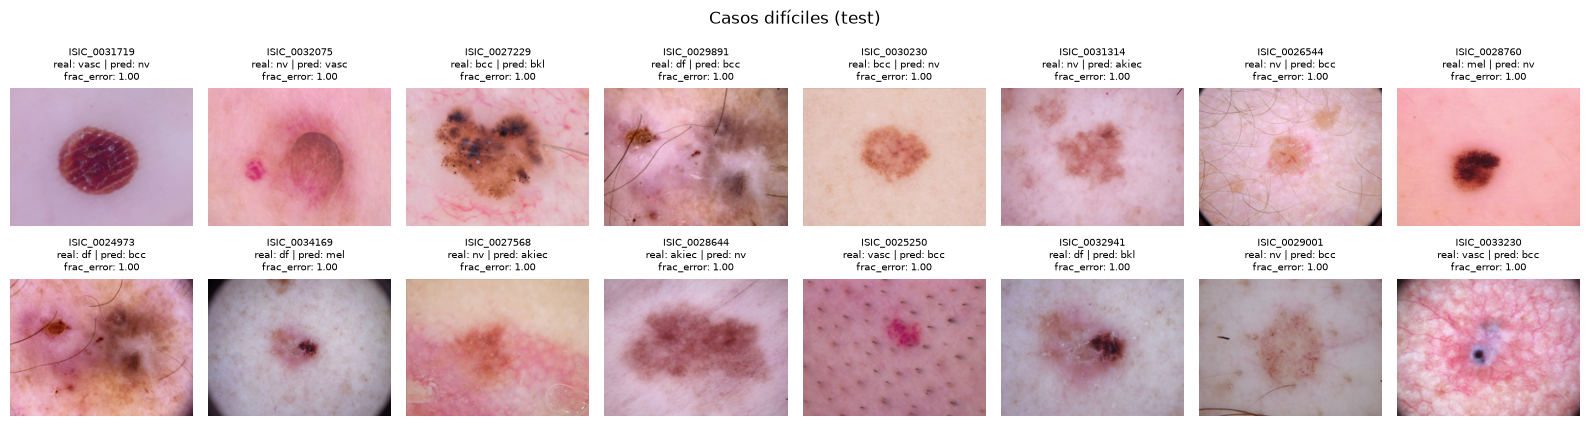

In [34]:
show(evaluation.plot_case_grid(cfg, dificiles, "pred_erronea_frecuente", "frac_error",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Casos difíciles (test)"))

Errores con mayor confianza: una fila por imagen, con la corrida en que la probabilidad de la clase
predicha fue mayor.

In [35]:
errores_confiados = evaluation.confident_errors(pred_test, cfg_dificiles["grid_n"])
errores_confiados

,image_id,run,label,pred,confidence
0,ISIC_0032075,s0_f1,nv,vasc,1.000000
1,ISIC_0026506,s0_f4,mel,vasc,0.999986
2,ISIC_0028760,s0_f2,mel,nv,0.999976
3,ISIC_0030070,s0_f2,vasc,nv,0.999398
4,ISIC_0033230,s0_f2,vasc,bcc,0.999384
5,ISIC_0026433,s0_f2,bcc,bkl,0.997907
6,ISIC_0024539,s0_f1,akiec,bkl,0.997834
7,ISIC_0027229,s0_f4,bcc,bkl,0.997153
8,ISIC_0028098,s0_f2,nv,bkl,0.997114
9,ISIC_0032090,s0_f2,nv,bcc,0.996486


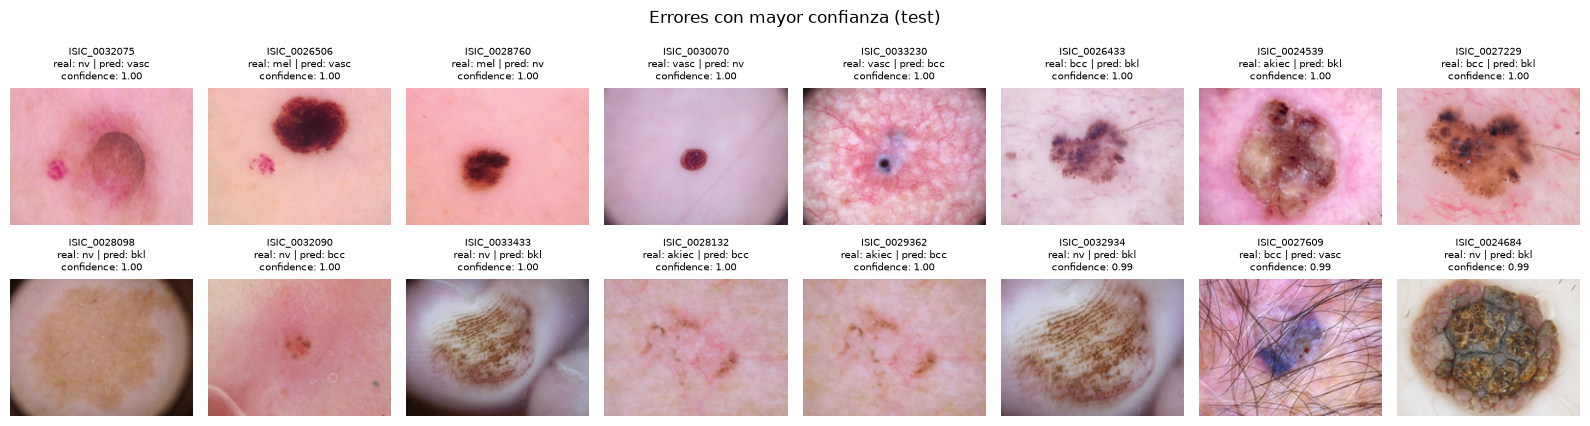

In [36]:
show(evaluation.plot_case_grid(cfg, errores_confiados, "pred", "confidence",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Errores con mayor confianza (test)"))

### 6.5 Calibración

ECE de cada corrida en test (intervalos de igual ancho en la confianza, como `train.ece_bins`), con
la confianza media y la exactitud.

In [37]:
evaluation.calibration_by_run(pred_test, cfg_eval["calibration_bins"])

,ece,confianza_media,exactitud
s0_f0,0.047058,0.664875,0.696716
s0_f1,0.038242,0.765862,0.737247
s0_f2,0.052095,0.804716,0.752621
s0_f3,0.041317,0.646876,0.638015
s0_f4,0.042844,0.761698,0.724668
mean,0.044311,0.728806,0.709853
std,0.005387,0.068951,0.045089


Diagrama de fiabilidad: exactitud frente a confianza media por intervalo, una línea por corrida y
una con todas las corridas juntas; debajo, el histograma de confianzas.

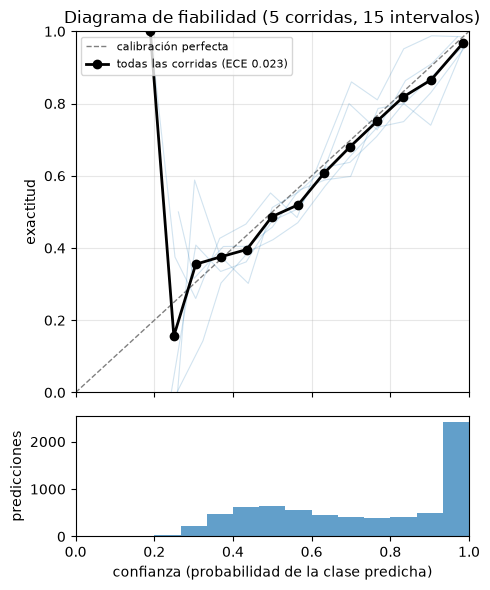

In [38]:
show(evaluation.plot_reliability(pred_test, cfg_eval["calibration_bins"]))

Valores por intervalo con todas las corridas juntas.

In [39]:
evaluation.pooled_reliability(pred_test, cfg_eval["calibration_bins"])

,desde,hasta,n,confianza_media,exactitud,brecha
0,0.000000,0.066667,0,NaN,NaN,NaN
1,0.066667,0.133333,0,NaN,NaN,NaN
2,0.133333,0.200000,2,0.189996,1.000000,0.810004
3,0.200000,0.266667,32,0.249679,0.156250,0.093429
4,0.266667,0.333333,214,0.305412,0.355140,0.049729
5,0.333333,0.400000,482,0.368461,0.375519,0.007058
6,0.400000,0.466667,629,0.435132,0.395866,0.039265
7,0.466667,0.533333,651,0.499041,0.486943,0.012098
8,0.533333,0.600000,560,0.565637,0.519643,0.045994
9,0.600000,0.666667,462,0.632325,0.608225,0.024100


### 6.6 Mapas de saliencia (Grad-CAM)

Grad-CAM respecto de la clase predicha sobre la capa `gradcam_layer` del YAML del modelo, con los
pesos de la corrida definitiva `evaluation.gradcam.run`. Muestra fija de test: por clase,
`per_class_correct` aciertos y `per_class_wrong` errores, elegidos con `sample_seed`.

In [40]:
cfg_gradcam = cfg_eval["gradcam"]
corrida_gradcam = gradcam.gradcam_run_dir(cfg, MODELO)
muestra = gradcam.sample_images(corrida_gradcam, cfg_gradcam["per_class_correct"],
                                cfg_gradcam["per_class_wrong"], cfg_gradcam["sample_seed"])
muestra

,image_id,label,pred,resultado,confidence
0,ISIC_0025780,akiec,akiec,acierto,0.869333
1,ISIC_0031198,akiec,akiec,acierto,0.635218
2,ISIC_0027254,akiec,df,error,0.305665
3,ISIC_0028372,akiec,df,error,0.557287
4,ISIC_0024897,bcc,bcc,acierto,0.970008
5,ISIC_0027825,bcc,bcc,acierto,0.952720
6,ISIC_0028155,bcc,bkl,error,0.313252
7,ISIC_0031378,bcc,df,error,0.406984
8,ISIC_0032335,bkl,bkl,acierto,0.259120
9,ISIC_0033539,bkl,bkl,acierto,0.247870


Cada par de filas muestra la imagen redimensionada como en el entrenamiento y, debajo, el mapa
superpuesto (rojo = mayor contribución a la clase predicha).

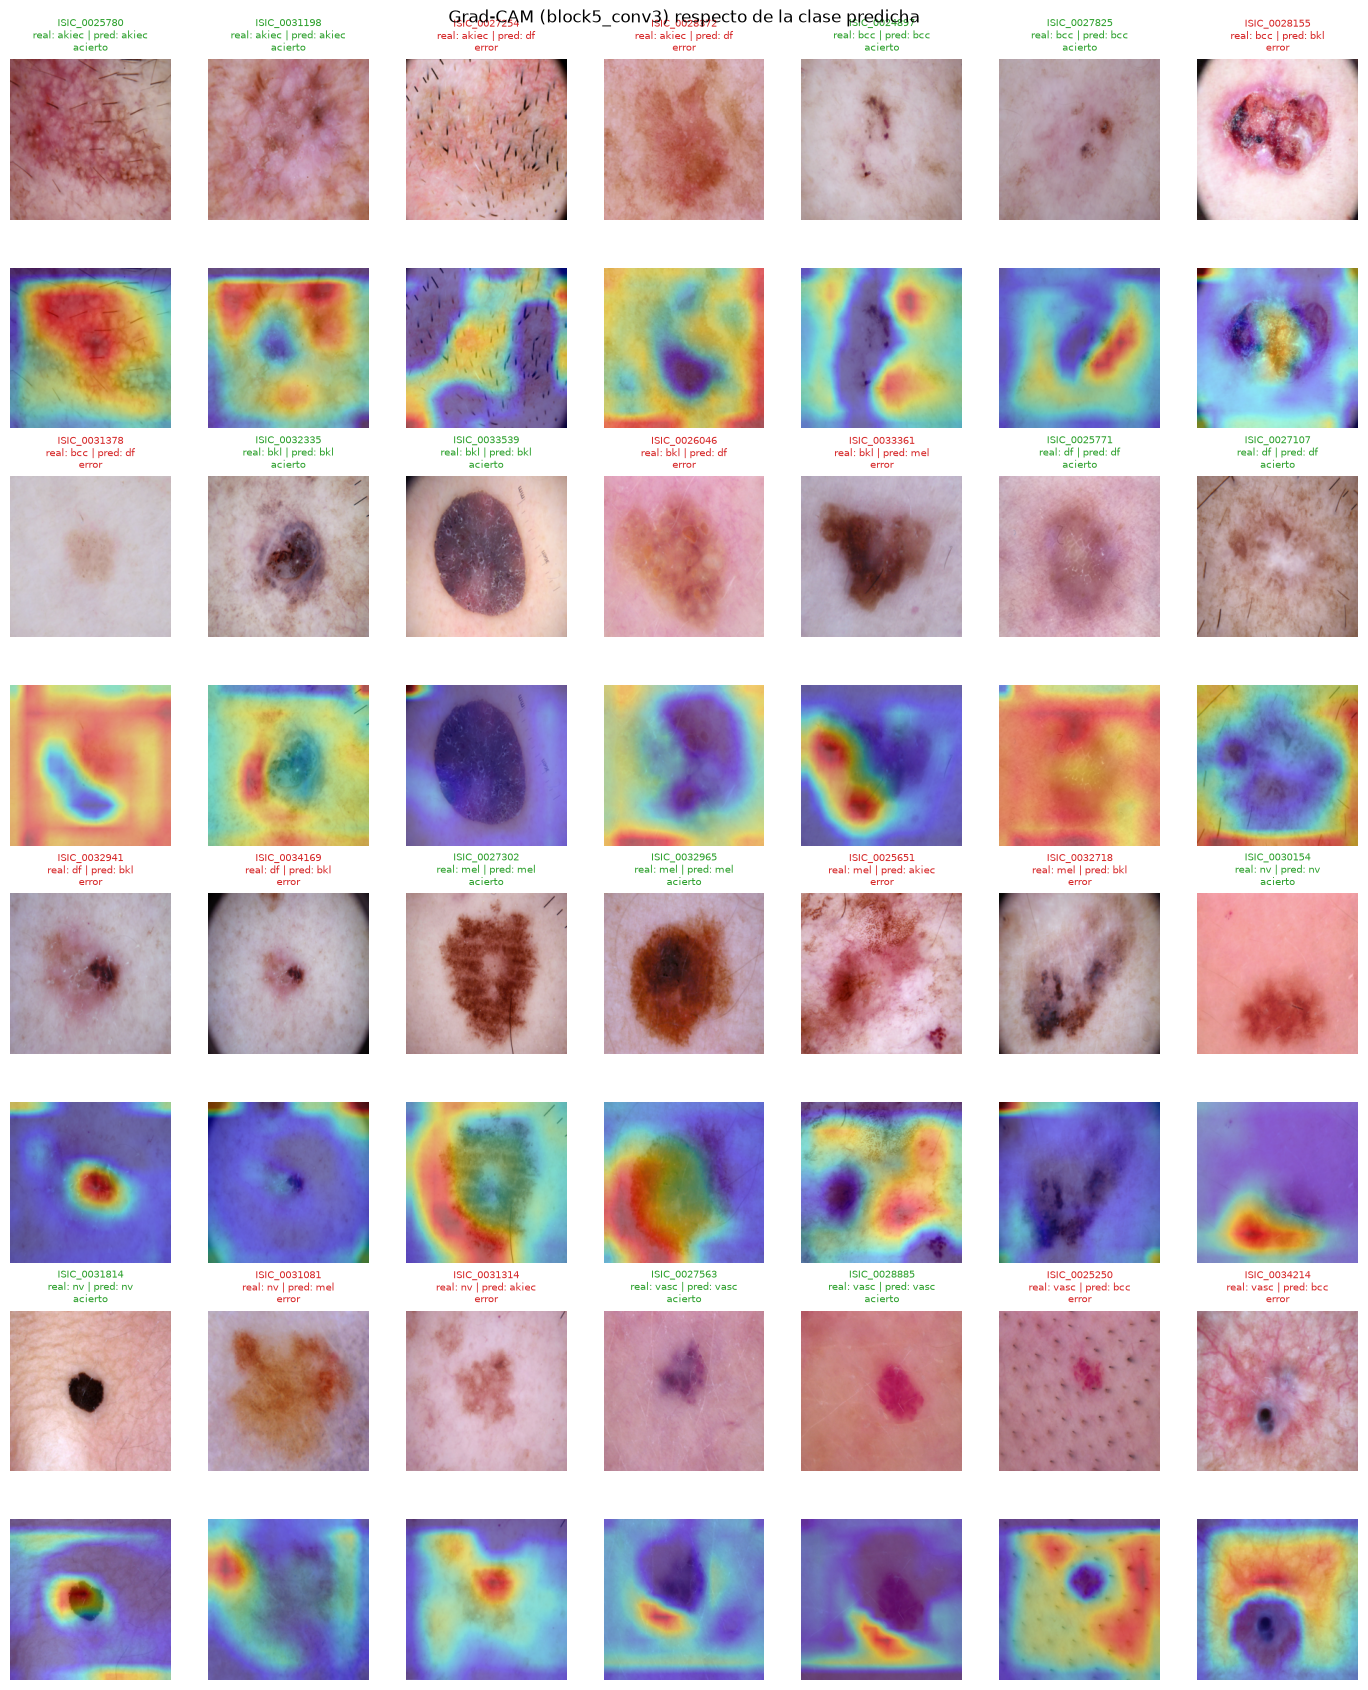

In [41]:
mapas = gradcam.compute_gradcam(cfg, MODELO, corrida_gradcam, muestra)
show(gradcam.plot_gradcam_grid(mapas, alpha=cfg_gradcam["alpha"], ncols=cfg_gradcam["ncols"]))